In [11]:
import numpy as np 

class SVM:
    def __init__(self, lr=0.01,n_interations = 1000,lamda_param=0.01):
        self.lr = lr
        self.n_interations = n_interations
        self.lamda_param = lamda_param
        self.weights = None
        self.bias = None
        
    def fit(self,X,y):
        y_ = np.where(y <= 0, -1, 1)
        n_samples, n_features = X.shape
        self.weights = np.zeros(n_features)
        self.bias = 0
        
        for _ in range(self.n_interations):
            for idx, x_i in enumerate(X):
                condition = y_[idx] * (np.dot(x_i, self.weights) - self.bias) >= 1
                if condition:
                    dw = self.lr*(2 * self.lamda_param * self.weights)
                    db = 0
                else:
                    dw = self.lr*(2 * self.lamda_param * self.weights - np.dot(x_i, y_[idx]))
                    db = self.lr * y_[idx]
                    
                self.weights -= self.lr * dw
                self.bias -= self.lr * db
    
    def predict(self,X):
        linear_output = np.dot(X, self.weights) + self.bias
        return np.sign(linear_output)

# TESTING THE MODEL

In [12]:

import matplotlib.pyplot as plt
from sklearn import datasets
from sklearn.model_selection import train_test_split 
dc = datasets.load_breast_cancer()
x_train, x_test, y_train, y_test = train_test_split(dc.data, dc.target, test_size=0.3, random_state=42)
cls = SVM(lr=0.001, n_interations=1000, lamda_param=0.01)
cls.fit(x_train, y_train)
y_pred = cls.predict(x_test)


In [13]:
def accuracy(y_true,y_pred):
    accuracy = np.sum(y_true==y_pred)/len(y_true)
    return accuracy

print("Accuracy:", accuracy(y_test, y_pred))

Accuracy: 0.6081871345029239


Accuracy: 0.9590643274853801


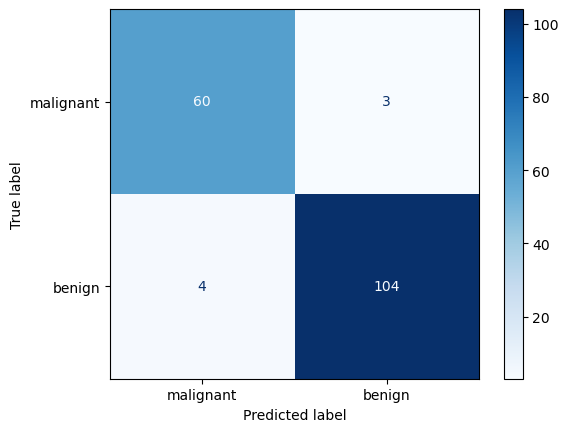

In [14]:
# plotting the accuracy
from sklearn.metrics import ConfusionMatrixDisplay, confusion_matrix

# Convert SVM labels (-1, 1) to the dataset labels (0, 1)
y_pred_labels = np.where(y_pred == -1, 0, 1)

print("Accuracy:", accuracy(y_test, y_pred_labels))

cm = confusion_matrix(y_test, y_pred_labels)
ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=dc.target_names
).plot(cmap="Blues", values_format="d")



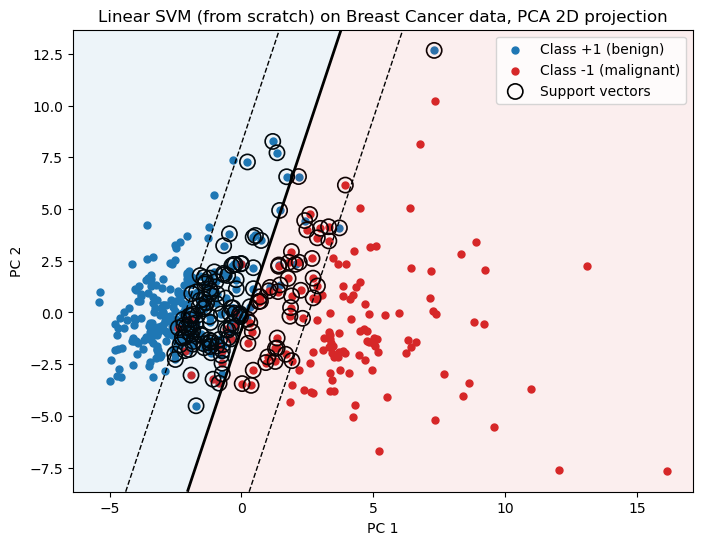

In [15]:
from sklearn.decomposition import PCA
from sklearn.preprocessing import StandardScaler

# 1. Reduce to 2D (scale first, since SVMs are sensitive to feature scale)
scaler = StandardScaler()
X_scaled = scaler.fit_transform(x_train)
X2 = PCA(n_components=2).fit_transform(X_scaled)
y2 = np.where(y_train <= 0, -1, 1)

# 2. Train the SVM on the 2D data
svm2d = SVM(lr=0.001, n_interations=1000, lamda_param=0.01)
svm2d.fit(X2, y_train)
w, b = svm2d.weights, svm2d.bias

# 3. Find support vectors: points on or inside the margin
scores = X2 @ w - b                      # same convention as the fit()
sv_mask = y2 * scores <= 1 + 1e-3

# 4. Plot
fig, ax = plt.subplots(figsize=(8, 6))
ax.scatter(X2[y2 == 1, 0], X2[y2 == 1, 1], c="tab:blue", s=25, label="Class +1 (benign)")
ax.scatter(X2[y2 == -1, 0], X2[y2 == -1, 1], c="tab:red", s=25, label="Class -1 (malignant)")

# circle the support vectors
ax.scatter(X2[sv_mask, 0], X2[sv_mask, 1], s=120, facecolors="none",
           edgecolors="k", linewidths=1.2, label="Support vectors")

# decision boundary (solid) and margins (dashed)
pad = 1
xx, yy = np.meshgrid(
    np.linspace(X2[:, 0].min() - pad, X2[:, 0].max() + pad, 300),
    np.linspace(X2[:, 1].min() - pad, X2[:, 1].max() + pad, 300),
)
Z = np.c_[xx.ravel(), yy.ravel()] @ w - b
Z = Z.reshape(xx.shape)
ax.contourf(xx, yy, Z, levels=[-np.inf, 0, np.inf], colors=["tab:red", "tab:blue"], alpha=0.08)
ax.contour(xx, yy, Z, levels=[-1, 0, 1], colors="k",
           linestyles=["--", "-", "--"], linewidths=[1, 2, 1])

ax.set_xlabel("PC 1"); ax.set_ylabel("PC 2")
ax.set_title("Linear SVM (from scratch) on Breast Cancer data, PCA 2D projection")
ax.legend()
plt.show()